# Getting started with mvmd-torch

**Multivariate Variational Mode Decomposition (MVMD)** splits a multichannel signal into a few oscillatory **modes**. Each mode is a narrow frequency band, and the modes are **shared by all channels**: the same rhythm, with its own amplitude on each channel. This is what we need for brain signals (EEG, MEG), where one rhythm is seen by many sensors at once.

In this notebook we build a synthetic 6-channel signal with three brain-like rhythms, decompose it with `mvmd`, and check that we get the rhythms back, channel by channel.

In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from mvmd_torch import mvmd

## 1. A synthetic multichannel signal

Three rhythms, as in a resting-state recording:

| Rhythm | Frequency | Amplitude across the 6 channels |
|---|---|---|
| alpha | 10 Hz | strong on the last channels (like the back of the head) |
| beta | 20 Hz | strong on the first channels |
| gamma | 40 Hz | weak and equal everywhere |

plus some noise. We know the truth, so we can check the decomposition.

signal shape (channels, samples): (6, 2000)


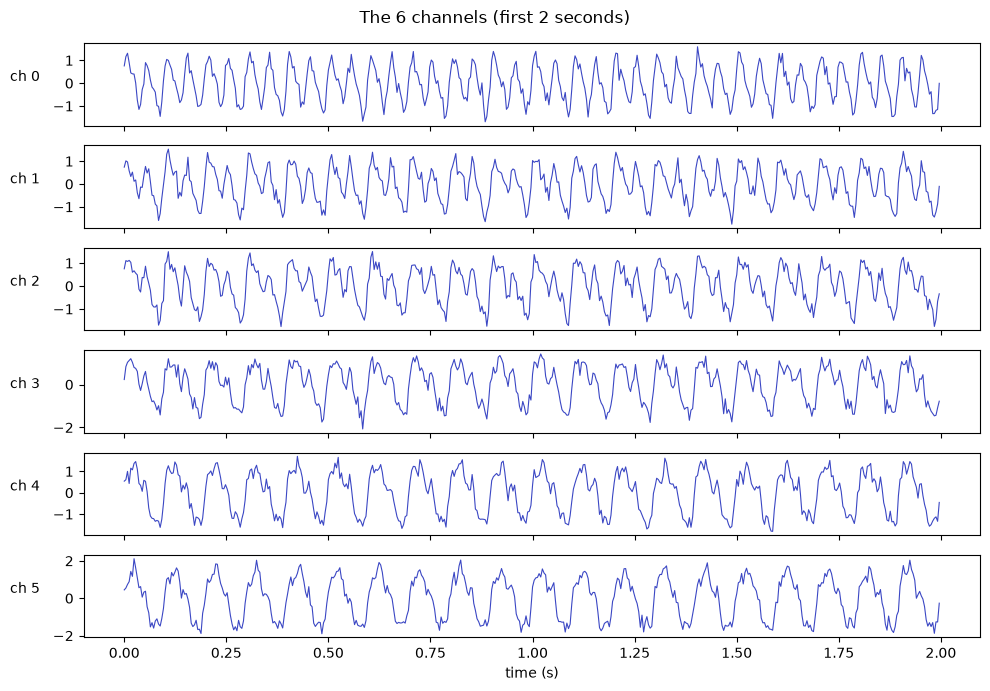

In [ ]:
fs = 250                                     # sampling rate (Hz)
t = np.arange(0, 8, 1 / fs)                  # 8 seconds
n_channels = 6
rng = np.random.default_rng(0)

amp_alpha = np.linspace(0.3, 1.5, n_channels)   # grows across channels
amp_beta = np.linspace(1.0, 0.2, n_channels)    # decreases across channels
amp_gamma = np.full(n_channels, 0.3)

alpha = amp_alpha[:, None] * np.sin(2 * np.pi * 10 * t)
beta = amp_beta[:, None] * np.sin(2 * np.pi * 20 * t + 0.5)
gamma = amp_gamma[:, None] * np.sin(2 * np.pi * 40 * t + 1.0)
x = alpha + beta + gamma + 0.2 * rng.standard_normal((n_channels, len(t)))
print("signal shape (channels, samples):", x.shape)

fig, axes = plt.subplots(n_channels, 1, figsize=(10, 7), sharex=True)
for c, ax in enumerate(axes):
    ax.plot(t[:500], x[c, :500], lw=0.8, color="#3B47C4")
    ax.set_ylabel(f"ch {c}", rotation=0, labelpad=20)
axes[-1].set_xlabel("time (s)")
fig.suptitle("The 6 channels (first 2 seconds)")
plt.tight_layout()
plt.show()

## 2. Decompose it

The main parameters:

- `K`: the number of modes to find (here 3);
- `alpha`: the bandwidth constraint, the larger the narrower each mode (2000 is a common value);
- `init=1`: start the centre frequencies uniformly spread; `tol` and `max_N` control the convergence.

`mvmd` runs on the GPU if PyTorch finds one, otherwise on the CPU.

In [ ]:
signal = torch.tensor(x, dtype=torch.float32)

start = time.perf_counter()
u, u_hat, omega = mvmd(signal, alpha=2000, tau=0, K=3, DC=False, init=1, tol=1e-7, max_N=500)
print(f"done in {time.perf_counter() - start:.2f} s on {u.device}")

u = u.cpu().numpy()                                  # (K, T, C): modes, samples, channels
centre_hz = omega.real.cpu().numpy().ravel() * fs    # omega is normalised: multiply by fs
order = np.argsort(centre_hz)                        # sort the modes by frequency
u, centre_hz = u[order], centre_hz[order]
print("modes shape (K, T, C):", u.shape)
print("centre frequencies (Hz):", centre_hz.round(2))

done in 2.51 s on cpu
modes shape (K, T, C): (3, 2000, 6)
centre frequencies (Hz): [ 9.97 20.01 40.03]


**The three centre frequencies come back at 10, 20 and 40 Hz**: MVMD found the three rhythms without being told where they were.

## 3. Look at the modes of two channels

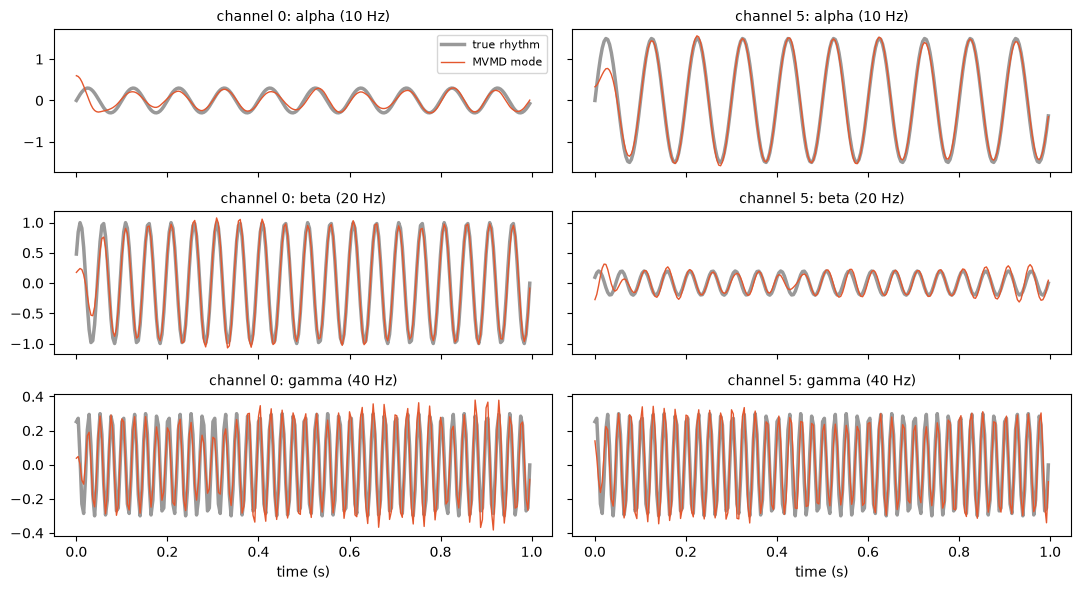

In [ ]:
names = ["alpha (10 Hz)", "beta (20 Hz)", "gamma (40 Hz)"]
truth = [alpha, beta, gamma]
fig, axes = plt.subplots(3, 2, figsize=(11, 6), sharex=True, sharey="row")
for col, c in enumerate([0, n_channels - 1]):
    for k in range(3):
        ax = axes[k, col]
        ax.plot(t[:250], truth[k][c, :250], color="#999999", lw=2.5, label="true rhythm")
        ax.plot(t[:250], u[k, :250, c], color="#E4572E", lw=1, label="MVMD mode")
        ax.set_title(f"channel {c}: {names[k]}", fontsize=10)
axes[0, 0].legend(loc="upper right", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
plt.tight_layout()
plt.show()

On channel 0, beta is strong and alpha is weak; on channel 5, it is the opposite. Each mode follows the true rhythm of **its own channel**.

## 4. Check it with numbers

Two checks: the amplitude of each mode on each channel must follow the amplitudes we chose, and the modes must add up to the signal of the same channel (the difference should be noise).

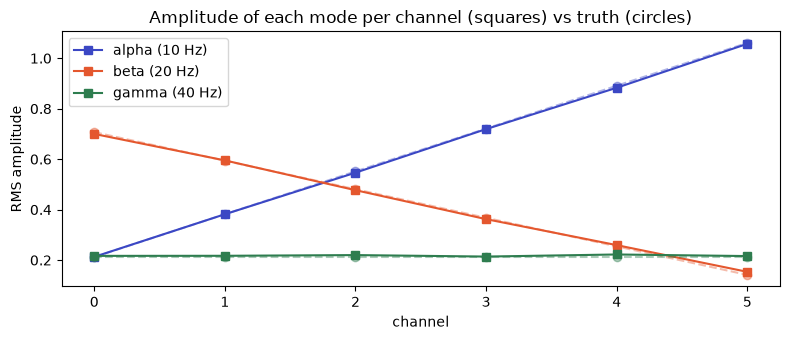

standard deviation of (signal - sum of the modes), per channel: [0.16  0.157 0.158 0.162 0.157 0.161]


In [ ]:
rms = np.sqrt((u ** 2).mean(axis=1))          # (K, C): amplitude of each mode on each channel
true_rms = np.stack([amp_alpha, amp_beta, amp_gamma]) / np.sqrt(2)

fig, ax = plt.subplots(figsize=(8, 3.5))
for k, color in zip(range(3), ["#3B47C4", "#E4572E", "#2E7D4F"]):
    ax.plot(true_rms[k], "o--", color=color, alpha=0.4)
    ax.plot(rms[k], "s-", color=color, label=names[k])
ax.set_xlabel("channel")
ax.set_ylabel("RMS amplitude")
ax.set_title("Amplitude of each mode per channel (squares) vs truth (circles)")
ax.legend()
plt.tight_layout()
plt.show()

residual = x - u.sum(axis=0).T
print("standard deviation of (signal - sum of the modes), per channel:", residual.std(axis=1).round(3))

The amplitudes of the modes follow the truth channel by channel, and what is left after removing the three modes is noise: a standard deviation of about 0.16, a bit less than the 0.2 we added, because each mode also keeps the small part of the noise that falls inside its own frequency band.

## Where to go next

- Choose `K` by looking at the spectrum of your signal: too few modes merge rhythms, too many split one rhythm in two.
- Increase `alpha` for narrower modes, decrease it for wider ones.
- On real EEG or MEG, standardise each channel first (z-score), as the amplitudes of sensors can differ a lot.

This implementation was written for the analysis of resting-state MEG in my Master's thesis, *Improved multifractal analysis of brain oscillations in MEG time series* (2025).